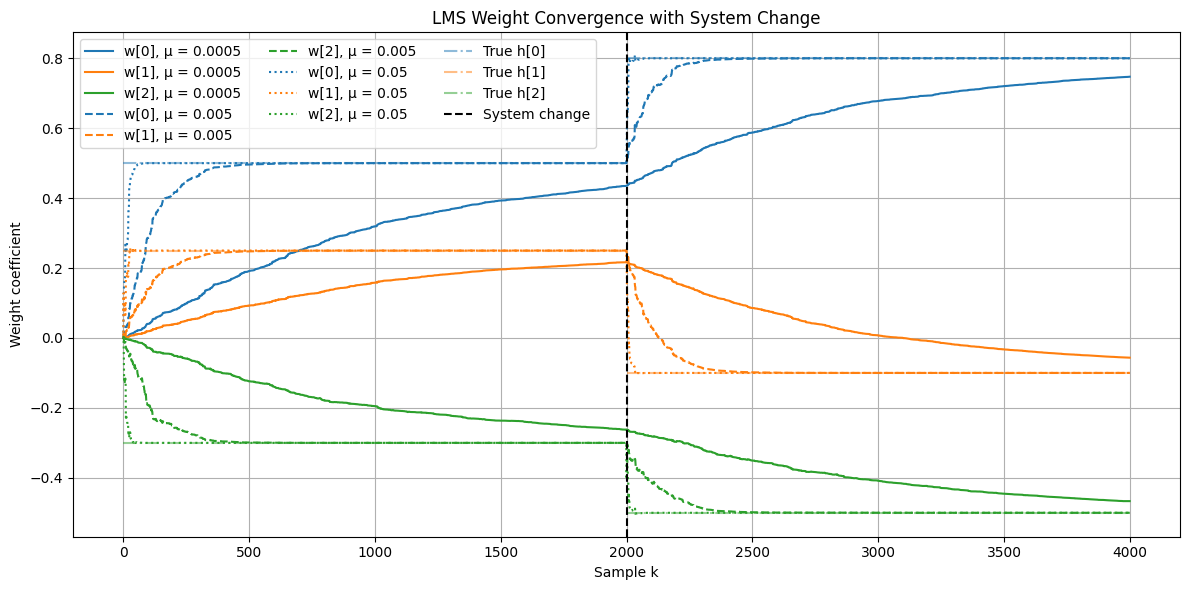

In [7]:
import numpy as np
import matplotlib.pyplot as plt


N = 4000
change_point = 2000


M = 3 #taps
mu_values = [0.0005, 0.005, 0.05]

# h = np.array([0.5, 0.25, -0.3])
h1 = np.array([0.5,0.25,-0.3])
h2 = np.array([0.8,-0.1,-0.5])
samples = np.arange(N)
seed = 11
noise_std = 1.0
rng = np.random.default_rng(seed)
k = np.arange(N)
x = rng.normal(0, noise_std, N)


d1 = np.convolve(x, h1, mode="full")[:N]
d2 = np.convolve(x, h2, mode="full")[:N]


d = np.where(np.arange(N) < change_point, d1, d2)

results = {}


for mu in mu_values:
    w = np.zeros(M) #inital weights are zero
    y = np.zeros(N) #adaptive filter output Y
    e = np.zeros(N) #error signal
    w_history = np.zeros((N,M))

    for k in range(M-1, N):
        #
        x_vec = x[k - M + 1:k + 1][::-1] #creates the X[k] vector 
        #extracts M samples from x, including the current samples
        #the reverses the order [::-1]
        
        #adaptive filter output
        y[k] = np.dot(w,x_vec) # W[k]*X[k] to apply the filter

        #calculate error
        e[k] = d[k] - y[k]

        #update the weights
        w = w + 2 * mu * e[k] * x_vec

        #store weights 
        w_history[k] = w
        results[mu] = {
        "w_history": w_history.copy(),
        "y": y.copy(),
        "e": e.copy()
    }



fig, ax = plt.subplots(figsize=(12, 6))

linestyles = ['-', '--', ':']
colors = plt.cm.tab10.colors

for i, mu in enumerate(mu_values):

    for m in range(M):

        ax.plot(
            results[mu]["w_history"][:, m],
            color=colors[m % len(colors)],
            linestyle=linestyles[i],
            label=f"w[{m}], μ = {mu}"
        )

# True system coefficients
for m in range(M):
    ax.hlines(
        h1[m], 0, change_point,
        color=colors[m % len(colors)],
        linestyle='-.',
        alpha=0.5,
        label=f"True h[{m}]"
    )

    ax.hlines(
        h2[m], change_point, N-1,
        color=colors[m % len(colors)],
        linestyle='-.',
        alpha=0.5
    )

# Mark system change
ax.axvline(
    change_point,
    color='black',
    linestyle='--',
    label='System change'
)

ax.set_xlabel("Sample k")
ax.set_ylabel("Weight coefficient")
ax.set_title("LMS Weight Convergence with System Change")
ax.legend(ncol=3)
ax.grid(True)

plt.tight_layout()
plt.show()

